In [7]:
from typing import TypedDict, List, Optional
from langgraph.graph import StateGraph, START, END
import random

In [8]:
class GameState(TypedDict):
    player_name: str
    guesses: List[int]
    attempts: int
    lower_bound: int
    upper_bound: int
    secret_number: Optional[int]
    hint: Optional[str]

In [9]:
def setup_node(state: GameState) -> GameState:
    """Setup the game and choose a secret number."""
    state["secret_number"] = random.randint(1, 20)
    state["guesses"] = []
    state["attempts"] = 0
    state["hint"] = None
    print(f"--- Game Started for {state['player_name']} ---")
    print(f"[Setup] Secret number picked: {state['secret_number']}\n")
    return state

def guess_node(state: GameState) -> GameState:
    """Calculate the next guess using bounds."""
    low = state["lower_bound"]
    high = state["upper_bound"]

    next_guess = (low + high) // 2

    state["guesses"].append(next_guess)
    state["attempts"] += 1
    return state

def hint_node(state: GameState) -> GameState:
    """Compare guess to secret number and adjust bounds."""
    last_guess = state["guesses"][-1]
    secret = state["secret_number"]

    print(f"Attempt #{state['attempts']}: System guessed {last_guess}")

    if last_guess == secret:
        state["hint"] = "correct"
        print("Correct! The number has been found.")
    elif last_guess < secret:
        state["hint"] = "higher"
        state["lower_bound"] = last_guess + 1
        print(f"Hint: Higher! (Adjusting lower bound to {state['lower_bound']})")
    else:
        state["hint"] = "lower"
        state["upper_bound"] = last_guess - 1
        print(f"Hint: Lower! (Adjusting upper bound to {state['upper_bound']})")

    print("-" * 50)
    return state

def determine_next_step(state: GameState) -> str:
    """Check if the game should continue or stop."""
    if state["hint"] == "correct":
        return "exit"

    if state["attempts"] >= 7:
        print("Reached maximum limits of 7 guesses. Game Over!")
        return "exit"

    return "loop"


In [10]:
graph = StateGraph(GameState)

SETUP_STEP = "setup"
GUESS_STEP = "guess"
HINT_STEP = "hint"

graph.add_node(SETUP_STEP, setup_node)
graph.add_node(GUESS_STEP, guess_node)
graph.add_node(HINT_STEP, hint_node)

graph.add_edge(START, SETUP_STEP)
graph.add_edge(SETUP_STEP, GUESS_STEP)
graph.add_edge(GUESS_STEP, HINT_STEP)

graph.add_conditional_edges(
    HINT_STEP,
    determine_next_step,
    {
        "loop": GUESS_STEP,
        "exit": END
    }
)

app = graph.compile()

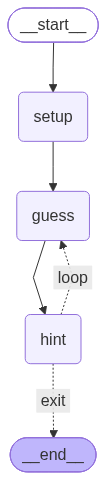

In [11]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [12]:
initial_input: GameState = {
    "player_name": "Student",
    "guesses": [],
    "attempts": 0,
    "lower_bound": 1,
    "upper_bound": 20,
    "secret_number": None,
    "hint": None
}

final_game_state = app.invoke(initial_input)
print(f"Total Attempts Used: {final_game_state['attempts']}")
print(f"All Guesses Tried:   {final_game_state['guesses']}")

--- Game Started for Student ---
[Setup] Secret number picked: 11

Attempt #1: System guessed 10
Hint: Higher! (Adjusting lower bound to 11)
----------------------------------------
Attempt #2: System guessed 15
Hint: Lower! (Adjusting upper bound to 14)
----------------------------------------
Attempt #3: System guessed 12
Hint: Lower! (Adjusting upper bound to 11)
----------------------------------------
Attempt #4: System guessed 11
Correct! The number has been found.
----------------------------------------
Total Attempts Used: 4
All Guesses Tried:   [10, 15, 12, 11]
